# Understanding QKV Attention From Scratch in **PyTorch**
-Aditya Shankar Pal

## 1. Introduction

### Objective

In this tutorial, we will implement the core attention mechanism used in transformers completely from scratch.

By the end of this notebook, you will understand:

- What Query, Key, and Value vectors are
- How attention scores are computed
- Why scaling is required
- How softmax converts scores into probabilities
- How self-attention works
- How multi-head attention extends the idea
- How transformers use QKV attention

### 2. Import libraries

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math

### 3. Create Toy Input Embeddings

Suppose we have 4 words, each represented by an embedding vector of dimension 8.

In [2]:
torch.manual_seed(42)
x = torch.randn(4, 8)
print(x)
print(x.shape)

tensor([[ 1.9269,  1.4873,  0.9007, -2.1055,  0.6784, -1.2345, -0.0431, -1.6047],
        [-0.7521,  1.6487, -0.3925, -1.4036, -0.7279, -0.5594, -0.7688,  0.7624],
        [ 1.6423, -0.1596, -0.4974,  0.4396, -0.7581,  1.0783,  0.8008,  1.6806],
        [ 1.2791,  1.2964,  0.6105,  1.3347, -0.2316,  0.0418, -0.2516,  0.8599]])
torch.Size([4, 8])


### 4. Create Q, K, V Projection Matrices

In transformers, Q, K, and V are learned linear transformations.



In [3]:
embed_dim = 8

W_Q = nn.Linear(embed_dim, embed_dim, bias=False)
W_K = nn.Linear(embed_dim, embed_dim, bias=False)
W_V = nn.Linear(embed_dim, embed_dim, bias=False)

### 5. Generate Query, Key, and Value Matrices

In [4]:
Q = W_Q(x)
K = W_K(x)
V = W_V(x)
print("Q shape:", Q.shape)
print("K shape:", K.shape)
print("V shape:", V.shape)

Q shape: torch.Size([4, 8])
K shape: torch.Size([4, 8])
V shape: torch.Size([4, 8])


### 6. Compute Attention Scores
Attention scores determine how much each token attends to every other token.

$$QK^T$$

In [5]:
scores = torch.matmul(Q, K.T)
print(scores)
print(scores.shape)

tensor([[ 1.2523,  0.0423, -0.4101,  0.6033],
        [-0.6610,  0.1095, -0.1882,  0.6961],
        [ 0.3460, -0.5986, -0.5688, -2.4501],
        [-0.2937,  0.9701,  1.8560,  0.0310]], grad_fn=<MmBackward0>)
torch.Size([4, 4])


### 7. Scale the Attention Scores
Without scaling, large dot products can destabilize softmax.

$$\frac{QK^T}{\sqrt{d_k}}$$

In [6]:
d_k = K.shape[-1]

scaled_scores = scores / math.sqrt(d_k)

print(scaled_scores)

tensor([[ 0.4428,  0.0150, -0.1450,  0.2133],
        [-0.2337,  0.0387, -0.0665,  0.2461],
        [ 0.1223, -0.2116, -0.2011, -0.8662],
        [-0.1039,  0.3430,  0.6562,  0.0110]], grad_fn=<DivBackward0>)


### 8. Apply Softmax

Convert scores into probabilities.

In [7]:
attention_weights = F.softmax(scaled_scores, dim=-1)
print(attention_weights)

tensor([[0.3331, 0.2171, 0.1850, 0.2648],
        [0.1957, 0.2569, 0.2313, 0.3161],
        [0.3556, 0.2547, 0.2574, 0.1323],
        [0.1717, 0.2685, 0.3672, 0.1926]], grad_fn=<SoftmaxBackward0>)


### 9. Compute Final Attention Output

$$Attention = softmax(QK^T)V$$

In [8]:
attention_output = torch.matmul(attention_weights, V)
print(attention_output)
print(attention_output.shape)

tensor([[ 0.7068, -0.1789,  0.0215,  0.4855,  0.6577, -0.4675,  0.1549,  0.0205],
        [ 0.6226, -0.2538, -0.1157,  0.3893,  0.6098, -0.5600,  0.3241,  0.0212],
        [ 0.7434, -0.1621,  0.0762,  0.4636,  0.6509, -0.5292,  0.0863,  0.0480],
        [ 0.6316, -0.2643, -0.1571,  0.3258,  0.5874, -0.7131,  0.2960,  0.0566]],
       grad_fn=<MmBackward0>)
torch.Size([4, 8])


### 10. Full QKV Attention Function

Now combine everything into one reusable function.

In [9]:
def scaled_dot_product_attention(Q, K, V):
    d_k = K.shape[-1]
    scores = torch.matmul(Q, K.transpose(-2, -1))
    scaled_scores = scores / math.sqrt(d_k)
    attention_weights = F.softmax(scaled_scores, dim=-1)
    output = torch.matmul(attention_weights, V)
    return output, attention_weights

### 11. Run the Attention Function

In [10]:
output, weights = scaled_dot_product_attention(Q, K, V)

print("Output shape:", output.shape)
print("Weights shape:", weights.shape)
print("Output:", output)
print("Weights:", weights)

Output shape: torch.Size([4, 8])
Weights shape: torch.Size([4, 4])
Output: tensor([[ 0.7068, -0.1789,  0.0215,  0.4855,  0.6577, -0.4675,  0.1549,  0.0205],
        [ 0.6226, -0.2538, -0.1157,  0.3893,  0.6098, -0.5600,  0.3241,  0.0212],
        [ 0.7434, -0.1621,  0.0762,  0.4636,  0.6509, -0.5292,  0.0863,  0.0480],
        [ 0.6316, -0.2643, -0.1571,  0.3258,  0.5874, -0.7131,  0.2960,  0.0566]],
       grad_fn=<MmBackward0>)
Weights: tensor([[0.3331, 0.2171, 0.1850, 0.2648],
        [0.1957, 0.2569, 0.2313, 0.3161],
        [0.3556, 0.2547, 0.2574, 0.1323],
        [0.1717, 0.2685, 0.3672, 0.1926]], grad_fn=<SoftmaxBackward0>)


### 12. Visualize Attention Matrix

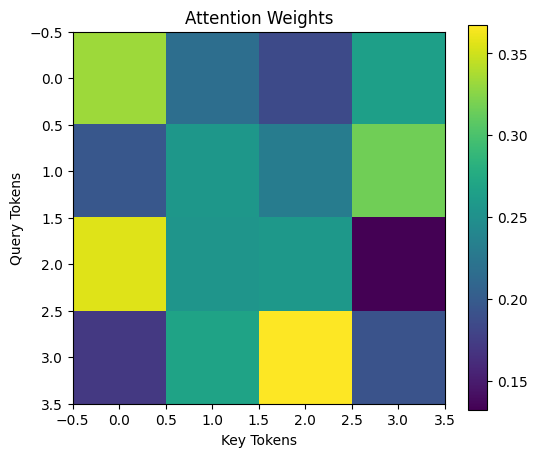

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))
plt.imshow(weights.detach().numpy())
plt.colorbar()
plt.title("Attention Weights")
plt.xlabel("Key Tokens")
plt.ylabel("Query Tokens")
plt.show()

### 13. Understanding Self-Attention

In self-attention:

- Q comes from input sequence
- K comes from input sequence
- V comes from input sequence

Thus every token attends to every other token.

### 14. Implement Multi-Head Attention

Instead of one attention mechanism, transformers use multiple heads.

Benefits:

- Learn different relationships
- Capture syntax and semantics simultaneously

### 15. Multi-Head Attention From Scratch

In [12]:
class MultiHeadAttention(nn.Module):
    def __init__(self, embed_dim, num_heads):
        super().__init__()
        assert embed_dim % num_heads == 0
        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        self.W_Q = nn.Linear(embed_dim, embed_dim)
        self.W_K = nn.Linear(embed_dim, embed_dim)
        self.W_V = nn.Linear(embed_dim, embed_dim)
        self.out_proj = nn.Linear(embed_dim, embed_dim)

    def forward(self, x):
        B, T, C = x.shape
        Q = self.W_Q(x)
        K = self.W_K(x)
        V = self.W_V(x)
        Q = Q.view(B, T, self.num_heads, self.head_dim)
        K = K.view(B, T, self.num_heads, self.head_dim)
        V = V.view(B, T, self.num_heads, self.head_dim)
        Q = Q.transpose(1, 2)
        K = K.transpose(1, 2)
        V = V.transpose(1, 2)
        scores = torch.matmul(Q, K.transpose(-2, -1))
        scores = scores / math.sqrt(self.head_dim)
        weights = F.softmax(scores, dim=-1)
        attention = torch.matmul(weights, V)
        attention = attention.transpose(1, 2)
        attention = attention.contiguous().view(B, T, C)
        out = self.out_proj(attention)
        return out

### 16. Test Multi-Head Attention

In [13]:
x = torch.randn(2, 5, 32)
mha = MultiHeadAttention(embed_dim=32, num_heads=4)
out = mha(x)
print(out.shape)

torch.Size([2, 5, 32])


## References
- Vaswani, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, A.N., Kaiser, Ł. and Polosukhin, I., 2017. Attention is all you need. Advances in neural information processing systems, 30.
- [Transformer code](https://github.com/facebookresearch/detr/blob/main/models/transformer.py)